# 7. Synthèse et recommandations

**Prédiction de la qualité des soudures**

Marie Gozlan, Jules Mortreux, Grégoire Pascual, Pétronille Tard

---

## Revenir à ce que l'énoncé demande vraiment

Avant de conclure, il faut relire la motivation que l'énoncé place en tête, car
elle détermine ce qui compte dans ce projet :

> *La connaissance liée à la qualité des soudures se transmet principalement
> d'expert à expert soudeur dont les industriels sont dépendants. Il y a un gros
> enjeu à acquérir de la connaissance via les données pour à la fois extraire et
> homogénéiser la connaissance experte mais également explorer de nouvelles
> connaissances via des patterns que l'on pourrait découvrir par l'exploration
> de la donnée.*

**La finalité de ce projet n'est pas de livrer un prédicteur, c'est d'extraire de
la connaissance.** Le modèle est un moyen. L'énoncé ne mentionne à aucun moment
une mise en production, un temps de réponse ou une contrainte de maintenance.

Cela a trois conséquences sur la façon de juger notre travail, et nous préférons
les énoncer que les laisser implicites.

**L'interprétabilité est un objectif, pas une qualité secondaire.** Un modèle
très performant dont on ne peut rien tirer ne répond pas à la demande.

**La complexité de la solution n'est pas un critère**, tant qu'elle reste
explicable. L'énoncé demande de conclure sur l'approche « la plus appropriée »,
et appropriée veut dire ici appropriée à l'extraction de connaissance.

**Un résultat négatif bien établi est un résultat.** Découvrir qu'une piste ne
mène nulle part est une connaissance acquise, et nous en avons plusieurs.

### Ce que cela valide dans nos choix

**C'est ce cadrage qui justifie, rétrospectivement, le choix le plus discutable
du projet : prédire les quatre propriétés séparément plutôt qu'un score.**

Un score de 0,48 n'est pas une connaissance transmissible. C'est un rang, il
demande une table de correspondance, et aucun soudeur expert ne peut le
confronter à son expérience.

« 520 mégapascals de limite d'élasticité et 28 % d'allongement » est en revanche
une phrase qu'un expert peut valider ou contester. **Nous avons donc traduit la
sortie du modèle dans le langage du métier, ce qui est littéralement ce que
l'énoncé appelle homogénéiser la connaissance experte.**

Et cela donne accès à un raisonnement que le score cachait : la section 4 montre
qu'augmenter le manganèse améliore le score **parce que** la résistance gagne
beaucoup sans que la ductilité coûte cher. Avec un score seul, on aurait
seulement constaté que la valeur monte.

## Comment ce notebook est organisé

Autour d'une distinction que nous tenons pour essentielle : séparer **ce que nos
données établissent** de **ce qu'elles suggèrent** et de **ce qu'elles ne peuvent
pas dire**. Un modèle entraîné sur un corpus observationnel ne produit pas de
lois physiques, et présenter ses sorties comme telles serait une faute.

## Le chemin parcouru

| notebook | ce qu'il établit |
|---|---|
| **1 données** | 1652 lignes décrivent 624 soudures, donc validation par groupes obligatoire. Les valeurs manquantes suivent le protocole expérimental. |
| **2 cible** | La qualité n'existe pas dans les données, elle est construite. La cible la mieux prédite est la pire définition. |
| **3 préparation** | Cinq décisions de préparation, chacune avec son coût mesuré. L'imputation aplatit l'analyse en composantes principales. Les groupes naturels ne sont pas des groupes de qualité. |
| **4 modélisation** | La coupure est entre linéaire et non linéaire. Prédire les quatre propriétés puis recomposer vaut mieux que prédire le score. |
| **5 approches écartées** | La classification est écartée par parcimonie, non par performance. La sélection de variables n'améliore pas la prédiction mais désigne les leviers. |
| **6 semi-supervisé** | La méthode fonctionne mais notre corpus n'est pas dans son domaine. Le facteur limitant est la classe de modèle, pas la supervision. |

In [1]:
from pathlib import Path
import ast
import json
import sys
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.ensemble import (BaggingRegressor, HistGradientBoostingRegressor,
                              RandomForestRegressor)
from sklearn.svm import SVR
from sklearn.impute import SimpleImputer
from sklearn.inspection import permutation_importance
from sklearn.metrics import mean_squared_error
from sklearn.model_selection import GroupShuffleSplit
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.tree import DecisionTreeRegressor, export_text

warnings.filterwarnings("ignore", category=FutureWarning)

ROOT = Path.cwd()
while not (ROOT / "data" / "raw").exists() and ROOT != ROOT.parent:
    ROOT = ROOT.parent
OUT = ROOT / "outputs" / "rendu7"
OUT.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(ROOT / "src"))
import export_processed as nettoyage

GRAINE = 42
plt.rcParams.update({"figure.dpi": 110, "axes.grid": True,
                     "grid.alpha": 0.3, "font.size": 10})

CATEGORIES = ["AC_DC", "Electrode_pol", "WeldType"]
RESISTANCE = ["YieldStrength_MPa", "UTS_MPa"]
DUCTILITE = ["Elongation_pct", "ReductionArea_pct"]
PROPRIETES = RESISTANCE + DUCTILITE
UNITES = {"YieldStrength_MPa": "MPa", "UTS_MPa": "MPa",
          "Elongation_pct": "%", "ReductionArea_pct": "%"}
NOMS = {"YieldStrength_MPa": "limite d'élasticité",
        "UTS_MPa": "résistance à la traction",
        "Elongation_pct": "allongement",
        "ReductionArea_pct": "striction"}
VARIABLES = nettoyage.COMPOSITION + nettoyage.PROCESS

donnees = pd.read_csv(ROOT / "outputs/rendu2/dataset_qualite.csv",
                      index_col="row_id",
                      dtype={c: str for c in CATEGORIES + ["WeldID", "partition"]},
                      keep_default_na=False, na_values=[""],
                      float_precision="round_trip")
dev = donnees["partition"] == "developpement"
X_dev = donnees.loc[dev, VARIABLES]
Y_dev = donnees.loc[dev, PROPRIETES]
score = donnees.loc[dev, "score_qualite"]
groupes = donnees.loc[dev, "groupe"]

bilan_4 = json.loads((ROOT / "outputs/rendu4/bilan.json").read_text(encoding="utf-8"))
bilan_5 = json.loads((ROOT / "outputs/rendu5/bilan.json").read_text(encoding="utf-8"))
bilan_6 = json.loads((ROOT / "outputs/rendu6/bilan.json").read_text(encoding="utf-8"))

print(f"Développement : {len(X_dev)} lignes, {groupes.nunique()} soudures.")
print(f"Test réservé  : {int((~dev).sum())} lignes.")

Développement : 527 lignes, 376 soudures.
Test réservé  : 123 lignes.


## 1. Le modèle retenu, et sa performance annoncée honnêtement

### 1.1 Ce qui est retenu

**Quatre modèles, un par propriété mécanique, et le score de qualité recalculé à
partir de leurs prédictions.** Les familles retenues sont celles du groupe de
tête du notebook 4.

Ce choix ne coûte rien en performance et apporte quatre informations que le score
seul ne donne pas : des valeurs en unités physiques directement lisibles, la
position de la soudure sur l'arbitrage entre résistance et ductilité, un réglage
séparé par propriété, et un gain de sept à vingt pourcents de lignes
exploitables selon la propriété.

### 1.2 Les chiffres, et lequel annoncer

C'est un point sur lequel nous voulons être précis, parce qu'il serait facile de
présenter le chiffre le plus flatteur.

In [2]:
lignes_performance = []
for propriete, détail in bilan_4["test"]["par_propriete"].items():
    lignes_performance.append({
        "propriété": propriete,
        "erreur (test)": détail["erreur"],
        "unité": détail["unité"],
        "R2 (test)": détail["R2"],
        "gain sur la référence (test)": détail["gain"],
    })
performance = pd.DataFrame(lignes_performance).set_index("propriété")
display(performance.round(4))

synthese_score = pd.Series({
    "gain en validation croisée (développement)":
        bilan_4["familles_sur_le_score"][
            max(bilan_4["familles_sur_le_score"],
                key=lambda n: bilan_4["familles_sur_le_score"][n]["gain"])]["gain"],
    "gain sur l'ensemble de test": bilan_4["test"]["gain_score"],
    "R2 sur l'ensemble de test": bilan_4["test"]["R2_score"],
}, name="score de qualité")
display(synthese_score.round(4).to_frame())

,erreur (test),unité,R2 (test),gain sur la référence (test)
propriété,,,,
limite d'élasticité,42.6425,MPa,0.6660,0.4313
résistance à la traction,24.9515,MPa,0.8827,0.6575
allongement,2.7896,%,0.6575,0.4154
striction,3.4185,%,0.7356,0.5051


,score de qualité
gain en validation croisée (développement),0.3886
gain sur l'ensemble de test,0.4429
R2 sur l'ensemble de test,0.6520


### 1.3 Le chiffre à annoncer est celui de la validation croisée

Le gain mesuré sur l'ensemble de test est **meilleur** que celui estimé par
validation croisée. Le notebook 4 a vérifié qu'il n'y a pas d'erreur de
protocole, et a identifié deux causes qui se cumulent : les modèles finaux
apprennent sur un quart de lignes de plus qu'en validation croisée, et
l'ensemble de test ne compte qu'une petite centaine de soudures, donc sa
variabilité est forte.

**Nous annonçons donc le chiffre de la validation croisée**, plus prudent et
calculé sur cinq découpages. Le chiffre de test sert à vérifier que notre
procédure de sélection n'a pas surajusté le développement, ce qui était son rôle.

### 1.4 Et une fiabilité inégale selon la propriété

**La résistance se prédit nettement mieux que la ductilité.** C'est
métallurgiquement cohérent : la résistance d'un acier est largement déterminée
par sa composition d'alliage, que nous avons en entrée, alors que la ductilité
dépend de la propreté du métal et de détails microstructuraux que le jeu de
données ne décrit pas.

**Conséquence pour tout usage : une prédiction de ductilité doit être annoncée
avec plus de réserve qu'une prédiction de résistance.** C'est une information que
le score agrégé ne pouvait pas donner, et c'est un argument supplémentaire en
faveur de l'approche par propriété.

## 2. Quelles variables comptent : quatre déterminations indépendantes

Pour formuler des recommandations, il ne suffit pas d'un classement de variables
obtenu par une seule méthode. Nous disposons de **quatre déterminations
indépendantes**, obtenues par des mécanismes sans rapport entre eux.

**L'importance par permutation**, calculée ci-dessous sur le modèle retenu. On
mélange au hasard les valeurs d'une seule variable entre les lignes et on regarde
de combien l'erreur augmente. Si mélanger une variable dégrade beaucoup les
prédictions, le modèle s'appuyait dessus.

Le cours recommande cette mesure plutôt que l'importance par décroissance
d'impureté, qui est biaisée en faveur des variables continues et à forte
cardinalité. Elle a sa propre limite, également signalée par le cours : lorsque
deux variables sont corrélées, mélanger l'une seule ne dégrade pas les
prédictions, le modèle retrouvant l'information dans l'autre. **L'importance des
variables corrélées est alors sous-estimée et répartie entre elles.**

**La sélection ascendante**, du notebook 5, qui ajoute les variables une à une
dans un modèle linéaire.

**Le Lasso**, du notebook 5, qui annule les coefficients par pénalisation.

**Un arbre de décision lisible**, calculé ci-dessous, dont les coupures désignent
les variables les plus discriminantes.

Si ces quatre méthodes désignent les mêmes variables, la conclusion est beaucoup
plus solide que celle de chacune prise isolément.

In [3]:
def creer_preparation(X_apprentissage, normaliser=False, seuil=0.25):
    """Préparation du notebook 3."""
    taux = X_apprentissage.notna().mean()
    retenues = taux[taux >= seuil].index.tolist()
    numeriques = [c for c in retenues if c not in CATEGORIES]
    categorielles = [c for c in retenues if c in CATEGORIES]
    etapes = [("mediane", SimpleImputer(strategy="median"))]
    if normaliser:
        etapes.append(("echelle", StandardScaler()))
    return ColumnTransformer([
        ("nombres", Pipeline(etapes), numeriques),
        ("categories", Pipeline([
            ("manquants", SimpleImputer(strategy="constant",
                                        fill_value="manquant")),
            ("encodage", OneHotEncoder(drop="first", handle_unknown="ignore",
                                       sparse_output=False)),
        ]), categorielles),
    ])


def poids_par_soudure(g):
    return (1 / g.map(g.value_counts())).to_numpy()


poids = poids_par_soudure(groupes)


def construire(famille, hyperparametres):
    """Reconstruit un modele du notebook 4 a partir de son nom de famille.

    Renvoie l'estimateur et les options de preparation qui vont avec. Leve une
    erreur si la famille est inconnue, plutot que de retomber silencieusement
    sur un modele par defaut comme le faisait la version precedente.
    """
    parametres = (ast.literal_eval(hyperparametres)
                  if isinstance(hyperparametres, str) else dict(hyperparametres))

    if "SVM" in famille:
        base = SVR(kernel="rbf")
        # Le notebook 4 enveloppe le SVM pour standardiser la cible quand il
        # travaille propriete par propriete, et pas sur le score. Le prefixe des
        # hyperparametres retenus dit lequel des deux cas s'applique.
        if any(cle.startswith("regressor__") for cle in parametres):
            estimateur = TransformedTargetRegressor(regressor=base,
                                                    transformer=StandardScaler())
        else:
            estimateur = base
        preparation = {"normaliser": True}
    elif "Boosting" in famille:
        estimateur = HistGradientBoostingRegressor(random_state=GRAINE,
                                                   early_stopping=False)
        preparation = {}
    elif "orêt" in famille:
        estimateur = RandomForestRegressor(random_state=GRAINE, n_jobs=-1)
        preparation = {}
    elif "Bagging" in famille:
        estimateur = BaggingRegressor(
            estimator=DecisionTreeRegressor(random_state=GRAINE),
            random_state=GRAINE, n_jobs=-1)
        preparation = {}
    else:
        raise ValueError(f"famille non reconstructible : {famille!r}")

    return estimateur.set_params(**parametres), preparation


# Controle avant tout calcul : toute famille nommee par le notebook 4 doit etre
# reconstructible, sinon on prefere echouer ici qu'entrainer le mauvais modele.
A_RECONSTRUIRE = [(d["famille"], d["hyperparametres"])
                  for d in bilan_4["modeles_retenus"].values()]
MEILLEURE_SUR_SCORE = max(bilan_4["familles_sur_le_score"],
                          key=lambda n: bilan_4["familles_sur_le_score"][n]["gain"])
A_RECONSTRUIRE.append(
    (MEILLEURE_SUR_SCORE,
     bilan_4["familles_sur_le_score"][MEILLEURE_SUR_SCORE]["hyperparametres"]))
for famille, hyper in A_RECONSTRUIRE:
    construire(famille, hyper)
print(f"{len(A_RECONSTRUIRE)} modeles du notebook 4 reconstructibles.")

# Le modele sur le score, pour l'importance par permutation. Il est reconstruit
# depuis le notebook 4 et non code en dur, pour que l'importance porte bien sur
# la famille retenue.
estimateur_score, prep_score = construire(
    MEILLEURE_SUR_SCORE,
    bilan_4["familles_sur_le_score"][MEILLEURE_SUR_SCORE]["hyperparametres"])
modele_score = Pipeline([
    ("preparation", creer_preparation(X_dev, **prep_score)),
    ("modele", estimateur_score)])
modele_score.fit(X_dev, score, modele__sample_weight=poids)
print(f"Importance calculée sur : {MEILLEURE_SUR_SCORE}")

resultat = permutation_importance(
    modele_score, X_dev, score, n_repeats=10, random_state=GRAINE, n_jobs=-1,
    scoring="neg_root_mean_squared_error")
importance = pd.Series(resultat.importances_mean,
                       index=X_dev.columns).sort_values(ascending=False)
ecart_importance = pd.Series(resultat.importances_std, index=X_dev.columns)

print("Importance par permutation, dix mélanges par variable :")
display(pd.DataFrame({"importance": importance.head(10),
                      "écart-type": ecart_importance[importance.head(10).index]
                      }).round(4))

5 modeles du notebook 4 reconstructibles.
Importance calculée sur : SVM de régression


Importance par permutation, dix mélanges par variable :


,importance,écart-type
Mn,0.0605,0.0030
Si,0.0276,0.0025
Nb_ppm,0.0225,0.0023
Ni,0.0165,0.0017
PWHT_T_C,0.0127,0.0011
Cr,0.0123,0.0026
C,0.0108,0.0011
Current_A,0.0105,0.0014
Mo,0.0101,0.0011
PWHT_time_h,0.0098,0.0009


In [4]:
# Un arbre de profondeur 3, pour lire des regles explicitement.
arbre = Pipeline([
    ("preparation", creer_preparation(X_dev)),
    ("modele", DecisionTreeRegressor(max_depth=3, min_samples_leaf=20,
                                     random_state=GRAINE))])
arbre.fit(X_dev, score, modele__sample_weight=poids)
noms_prepares = [n.split("__")[-1]
                 for n in arbre.named_steps["preparation"].get_feature_names_out()]

print("Règles apprises par un arbre de profondeur 3 :\n")
print(export_text(arbre.named_steps["modele"], feature_names=noms_prepares,
                  decimals=2))

Règles apprises par un arbre de profondeur 3 :

|--- Mn <= 1.35
|   |--- HeatInput_kJmm <= 2.86
|   |   |--- C <= 0.04
|   |   |   |--- value: [0.29]
|   |   |--- C >  0.04
|   |   |   |--- value: [0.39]
|   |--- HeatInput_kJmm >  2.86
|   |   |--- value: [0.24]
|--- Mn >  1.35
|   |--- P <= 0.02
|   |   |--- O_ppm <= 434.50
|   |   |   |--- value: [0.52]
|   |   |--- O_ppm >  434.50
|   |   |   |--- value: [0.44]
|   |--- P >  0.02
|   |   |--- value: [0.38]



In [5]:
# Le croisement des quatre methodes.
stabilite = pd.read_csv(ROOT / "outputs/rendu5/selection_rangs.csv",
                        index_col="rang")
variables_lasso = set(bilan_5["selection_de_variables"]["variables_lasso"])
sous_ensemble_bic = set(bilan_5["selection_de_variables"]["sous_ensemble_BIC"])
stables = bilan_5["selection_de_variables"]["variables_stables_sur_cinq_plis"]

# Les variables utilisees par l'arbre lisible.
modele_arbre = arbre.named_steps["modele"]
utilisees_arbre = {noms_prepares[i] for i in modele_arbre.tree_.feature
                   if i >= 0}

rang_selection = {stabilite.loc[r, "variable la plus fréquente"]: r
                  for r in stabilite.index}

convergence = pd.DataFrame({
    "rang, importance par permutation": {v: r + 1 for r, v
                                         in enumerate(importance.index)},
    "rang, sélection ascendante": rang_selection,
    "retenue par le Lasso": {v: v in variables_lasso for v in X_dev.columns},
    "utilisée par l'arbre lisible": {v: v in utilisees_arbre
                                     for v in X_dev.columns},
})
# Le tableau doit montrer toute variable designee par au moins une methode, et
# pas seulement les premieres de l'importance par permutation : une variable
# peut etre retenue par trois methodes et mal classee par la quatrieme.
designees = (set(importance.head(10).index) | set(rang_selection)
             | set(variables_lasso) | set(utilisees_arbre))
convergence = convergence.loc[[v for v in importance.index if v in designees]]
convergence.insert(0, "méthodes sur 4", (
    convergence["rang, importance par permutation"].le(10).astype(int)
    + convergence["rang, sélection ascendante"].notna().astype(int)
    + convergence["retenue par le Lasso"].astype(int)
    + convergence["utilisée par l'arbre lisible"].astype(int)))
convergence = convergence.sort_values(
    ["méthodes sur 4", "rang, importance par permutation"],
    ascending=[False, True])
display(convergence)

print(f"Variables choisies au même rang dans les cinq plis de la sélection "
      f"ascendante : {stables}")
print(f"Variables utilisées par l'arbre de profondeur 3 : "
      f"{sorted(utilisees_arbre)}")

,méthodes sur 4,"rang, importance par permutation","rang, sélection ascendante",retenue par le Lasso,utilisée par l'arbre lisible
Mn,4,1.0,1.0,True,True
HeatInput_kJmm,3,14.0,2.0,True,True
Si,2,2.0,NaN,True,False
PWHT_T_C,2,5.0,5.0,False,False
C,2,7.0,NaN,False,True
PWHT_time_h,2,10.0,NaN,True,False
Ti_ppm,2,21.0,4.0,True,False
Nb_ppm,1,3.0,NaN,False,False
Ni,1,4.0,NaN,False,False
Cr,1,6.0,NaN,False,False


Variables choisies au même rang dans les cinq plis de la sélection ascendante : ['Mn', 'HeatInput_kJmm']
Variables utilisées par l'arbre de profondeur 3 : ['C', 'HeatInput_kJmm', 'Mn', 'O_ppm', 'P']


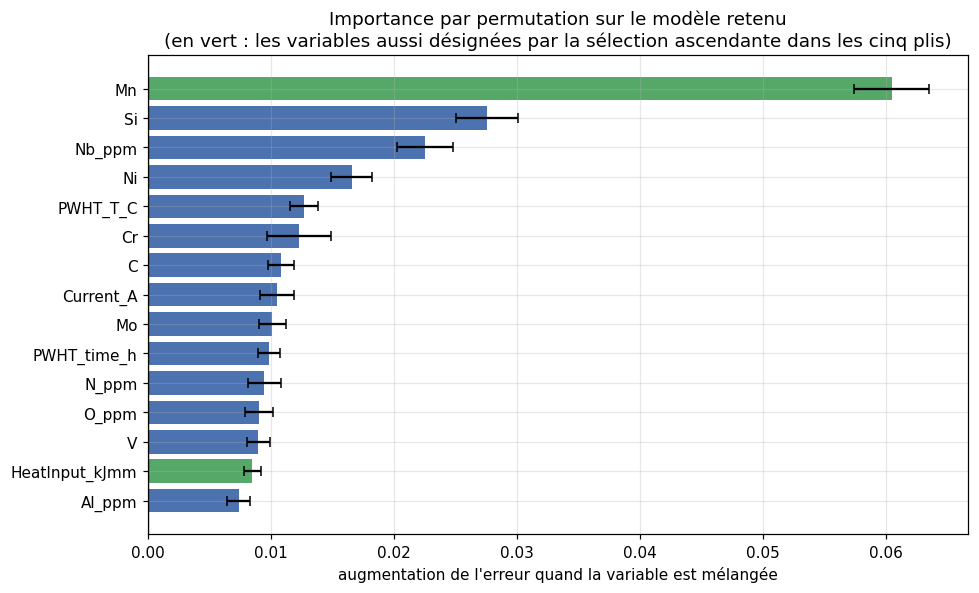

In [6]:
figure, axe = plt.subplots(figsize=(9, 5.5))
quinze = importance.head(15).iloc[::-1]
couleurs = ["#55A868" if v in stables else "#4C72B0" for v in quinze.index]
axe.barh(quinze.index, quinze.to_numpy(),
         xerr=ecart_importance[quinze.index].to_numpy(), capsize=3,
         color=couleurs)
axe.axvline(0, color="black", linewidth=0.8)
axe.set(xlabel="augmentation de l'erreur quand la variable est mélangée",
        title="Importance par permutation sur le modèle retenu\n"
              "(en vert : les variables aussi désignées par la sélection "
              "ascendante dans les cinq plis)")
figure.tight_layout()
figure.savefig(OUT / "importance_variables.png", dpi=150)
plt.show()

## 3. Les leviers, et leur lecture métallurgique

### 3.1 Ce sur quoi les méthodes s'accordent

Le tableau ci-dessus compte, pour chaque variable, combien des quatre méthodes
la désignent. Deux variables se détachent, et il faut dire exactement avec
quelle force.

**Le manganèse est désigné par les quatre méthodes sur quatre.** C'est la seule
variable dans ce cas, et c'est donc le seul résultat que nous tenons pour
pleinement établi. C'est métallurgiquement attendu : dans les aciers au
carbone-manganèse, qui constituent l'essentiel de ce corpus, le manganèse est
l'élément d'alliage principal. Il augmente la résistance et participe à la
désoxydation du bain de fusion.

**L'énergie de soudage est désignée par trois méthodes sur quatre** : rang 2 de
la sélection ascendante et stable dans les cinq plis sur cinq, retenue par le
Lasso, et utilisée par la deuxième coupure de l'arbre lisible. La seule méthode
qui ne la désigne pas est l'importance par permutation, où elle tombe au rang 14
sur 30.

**Cette dissidence s'explique, et l'explication est celle que le cours
annonce.** L'importance par permutation sous-estime les variables corrélées,
puisque mélanger l'une seule ne dégrade rien si le modèle retrouve
l'information dans une autre. Or l'énergie de soudage est précisément une
**combinaison que nous avons construite** à partir de la tension, de l'intensité
et de la vitesse, et l'intensité figure au rang 8 de cette même importance. Un
arbre doit choisir une variable par coupure, donc il attribue tout l'effet à
l'énergie de soudage ; un SVM à noyau gaussien, qui est lisse, répartit son
appui entre les variables de procédé corrélées.

**Et l'étude des leviers de la section 4 tranche en faveur d'un effet réel** :
faire varier l'énergie de soudage de 0,6 à 3,5 kilojoules par millimètre fait
baisser le score prédit de 0,41 à 0,32, de façon monotone. Une variable sans
effet ne produirait pas cela.

**Le traitement thermique post-soudage** vient ensuite, en température et en
durée, avec deux méthodes sur quatre.

### 3.2 Pourquoi cette seconde famille est la plus intéressante

**Les paramètres du procédé sont les seuls leviers réellement actionnables une
fois la nuance d'acier choisie.** Modifier la composition d'un métal d'apport
suppose de changer de produit ; modifier l'énergie apportée ou le traitement
thermique est un réglage d'atelier.

Le traitement thermique post-soudage est de surcroît le seul levier disponible
**après** que la soudure a été réalisée. C'est donc le plus directement
exploitable.

### 3.3 Ce que l'arbre lisible dit, et pourquoi c'est rassurant

Les règles de l'arbre de profondeur 3 se lisent directement : chaque ligne est
une condition sur une variable, et chaque feuille donne le score prédit pour les
soudures qui satisfont tout le chemin de conditions au-dessus d'elle.

**Le point important est que les coupures vont dans le sens attendu par la
métallurgie, sans qu'on l'ait dit au modèle.** Une teneur en manganèse plus
élevée améliore le score. Une énergie de soudage élevée le dégrade, ce qui est le
résultat classique : plus d'énergie apportée signifie un refroidissement plus
lent, donc une microstructure à gros grains, moins résistante et moins tenace.

**C'est un argument de validation d'une nature différente de tous les
précédents.** Les notebooks 2 à 4 vérifiaient la cohérence interne de nos
constructions ; ici nous vérifions leur **cohérence avec des connaissances
extérieures au jeu de données**. Un modèle qui conclurait que le phosphore
améliore la soudure serait suspect, quelles que soient ses performances.

**Et c'est aussi la réponse la plus directe à l'objectif de l'énoncé.** Retrouver
dans les données des régularités que la métallurgie connaît déjà, sans les avoir
fournies au modèle, c'est exactement **extraire la connaissance experte** à
partir des données plutôt que de la recueillir auprès d'un expert.

Cela donne de surcroît une indication sur le crédit à accorder au reste. Un
modèle qui retrouve seul ce que l'on sait déjà est plus crédible lorsqu'il
suggère quelque chose que l'on ne savait pas.

## 4. Interroger le modèle : une démonstration

Un modèle sert aussi à poser des questions que les données ne contiennent pas
directement. Nous prenons une soudure réelle et nous demandons au modèle ce que
donnerait une modification d'un seul paramètre, toutes choses égales par
ailleurs.

**C'est l'usage le plus directement utile à un industriel**, et c'est aussi celui
qui demande le plus de prudence. La section 5 explique pourquoi.

In [7]:
# Les quatre modeles par propriete, reentraines sur tout le developpement.
CONFIGURATIONS = {}
for propriete, détail in bilan_4["modeles_retenus"].items():
    CONFIGURATIONS[propriete] = détail["famille"]

propriete_par_nom = {v: k for k, v in NOMS.items()}
modeles_proprietes, references_rangs = {}, {}

def reference_rangs(valeurs, g):
    p = 1 / g.map(g.value_counts())
    table = pd.DataFrame({"valeur": valeurs, "poids": p}).dropna()
    masse = table.groupby("valeur")["poids"].sum()
    return (masse.index.to_numpy(),
            ((masse.cumsum() - masse / 2) / masse.sum()).to_numpy())

for nom_lisible, famille in CONFIGURATIONS.items():
    propriete = propriete_par_nom[nom_lisible]
    estimateur, prep = construire(
        famille, bilan_4["modeles_retenus"][nom_lisible]["hyperparametres"])
    pipeline = Pipeline([("preparation", creer_preparation(X_dev, **prep)),
                         ("modele", estimateur)])
    pipeline.fit(X_dev, Y_dev[propriete], modele__sample_weight=poids)
    modeles_proprietes[propriete] = pipeline
    references_rangs[propriete] = reference_rangs(Y_dev[propriete], groupes)

print(f"{len(modeles_proprietes)} modèles réentraînés sur le développement,")
print("avec la famille et les hyperparamètres retenus par le notebook 4 :")
for nom_lisible, famille in CONFIGURATIONS.items():
    hyper = bilan_4["modeles_retenus"][nom_lisible]["hyperparametres"]
    print(f"   {nom_lisible:26s} {famille}")
    print(f"   {'':26s} {hyper}")

4 modèles réentraînés sur le développement,
avec la famille et les hyperparamètres retenus par le notebook 4 :
   limite d'élasticité        SVM de régression
                              {'regressor__C': 100, 'regressor__epsilon': 0.02, 'regressor__gamma': 0.01}
   résistance à la traction   SVM de régression
                              {'regressor__C': 100, 'regressor__epsilon': 0.02, 'regressor__gamma': 0.01}
   allongement                SVM de régression
                              {'regressor__C': 10, 'regressor__epsilon': 0.1, 'regressor__gamma': 'scale'}
   striction                  SVM de régression
                              {'regressor__C': 100, 'regressor__epsilon': 0.1, 'regressor__gamma': 0.01}


In [8]:
def profil_predit(entrees):
    """Prédit les quatre propriétés et recompose le score."""
    valeurs, rangs = {}, {}
    for propriete, pipeline in modeles_proprietes.items():
        predit = pipeline.predict(entrees)
        valeurs[propriete] = predit
        rangs[propriete] = np.interp(predit, *references_rangs[propriete])
    tableau = pd.DataFrame(rangs)
    score_predit = np.sqrt(tableau[RESISTANCE].mean(axis=1)
                           * tableau[DUCTILITE].mean(axis=1))
    return pd.DataFrame(valeurs, index=entrees.index), score_predit.to_numpy()


# On choisit une soudure reelle, bien renseignee, du developpement.
completude = X_dev.notna().sum(axis=1)
reference_soudure = completude.idxmax()
base = X_dev.loc[[reference_soudure]]

valeurs_base, score_base = profil_predit(base)
print(f"Soudure de référence : ligne {reference_soudure}, "
      f"{int(completude.loc[reference_soudure])} variables renseignées sur "
      f"{len(VARIABLES)}")
print(f"Score réel mesuré  : {score.loc[reference_soudure]:.3f}")
print(f"Score prédit       : {score_base[0]:.3f}\n")
affichage = valeurs_base.T.rename(columns={reference_soudure: "prédit"})
affichage["mesuré"] = [donnees.loc[reference_soudure, p] for p in affichage.index]
affichage["unité"] = [UNITES[p] for p in affichage.index]
affichage.index = [NOMS[p] for p in affichage.index]
display(affichage.round(2))

Soudure de référence : ligne 1024, 28 variables renseignées sur 30
Score réel mesuré  : 0.294
Score prédit       : 0.321



row_id,prédit,mesuré,unité
limite d'élasticité,430.70,429.0,MPa
résistance à la traction,548.61,537.0,MPa
allongement,22.49,22.0,%
striction,74.07,75.0,%


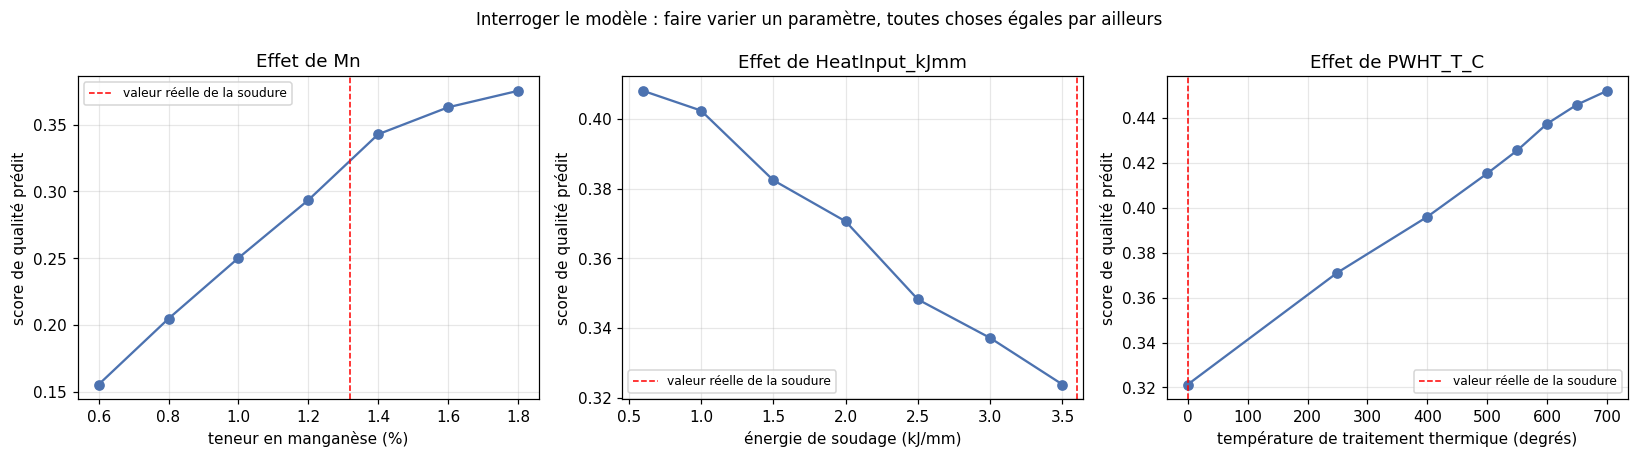


Mn :


,YieldStrength_MPa,UTS_MPa,Elongation_pct,ReductionArea_pct,score
0.6,355.60,479.53,24.94,79.65,0.16
0.8,373.72,496.16,24.36,78.29,0.20
1.0,394.06,514.85,23.68,76.78,0.25
1.2,416.42,535.43,22.94,75.12,0.29
1.4,440.53,557.70,22.19,73.35,0.34
1.6,466.06,581.40,21.49,71.50,0.36
1.8,492.67,606.24,20.86,69.60,0.38



HeatInput_kJmm :


,YieldStrength_MPa,UTS_MPa,Elongation_pct,ReductionArea_pct,score
0.6,445.81,536.86,23.57,79.32,0.41
1.0,443.60,537.65,23.41,79.00,0.40
1.5,441.00,539.14,23.20,78.43,0.38
2.0,438.54,541.06,22.98,77.67,0.37
2.5,436.14,543.29,22.79,76.73,0.35
3.0,433.72,545.70,22.63,75.62,0.34
3.5,431.21,548.13,22.51,74.34,0.32



PWHT_T_C :


,YieldStrength_MPa,UTS_MPa,Elongation_pct,ReductionArea_pct,score
0,430.70,548.61,22.49,74.07,0.32
250,444.70,560.34,24.03,73.50,0.37
400,453.72,568.14,24.93,72.99,0.40
500,459.86,573.55,25.46,72.60,0.42
550,462.94,576.29,25.70,72.39,0.43
600,466.03,579.05,25.92,72.17,0.44
650,469.10,581.83,26.12,71.94,0.45
700,472.16,584.60,26.30,71.70,0.45


In [9]:
# Effet d'une variation du manganese et du traitement thermique.
LEVIERS = {
    "Mn": ("teneur en manganèse (%)",
           [0.6, 0.8, 1.0, 1.2, 1.4, 1.6, 1.8]),
    "HeatInput_kJmm": ("énergie de soudage (kJ/mm)",
                       [0.6, 1.0, 1.5, 2.0, 2.5, 3.0, 3.5]),
    "PWHT_T_C": ("température de traitement thermique (degrés)",
                 [0, 250, 400, 500, 550, 600, 650, 700]),
}

figure, axes = plt.subplots(1, 3, figsize=(15, 4.2))
courbes = {}
for axe, (variable, (etiquette, valeurs)) in zip(axes, LEVIERS.items()):
    scores, details = [], []
    for valeur in valeurs:
        variante = base.copy()
        variante[variable] = float(valeur)
        proprietes, s = profil_predit(variante)
        scores.append(s[0])
        details.append(proprietes.iloc[0].to_dict())
    courbes[variable] = pd.DataFrame(details, index=valeurs).assign(score=scores)

    axe.plot(valeurs, scores, marker="o", color="#4C72B0")
    valeur_reelle = base[variable].iloc[0]
    if pd.notna(valeur_reelle):
        axe.axvline(valeur_reelle, color="red", linestyle="--", linewidth=1,
                    label="valeur réelle de la soudure")
        axe.legend(fontsize=8)
    axe.set(xlabel=etiquette, ylabel="score de qualité prédit",
            title=f"Effet de {variable}")

figure.suptitle("Interroger le modèle : faire varier un paramètre, "
                "toutes choses égales par ailleurs", fontsize=11)
figure.tight_layout()
figure.savefig(OUT / "leviers.png", dpi=150)
plt.show()

for variable in LEVIERS:
    print(f"\n{variable} :")
    display(courbes[variable].round(2))

### Ce que la démonstration montre, et la prudence qu'elle exige

Les courbes donnent le sens et l'ampleur de l'effet que le modèle attribue à
chaque paramètre, et le détail par propriété montre **par quel mécanisme** le
score bouge : une variation peut améliorer la résistance en dégradant la
ductilité, auquel cas le score agrégé bouge peu alors que le produit change
beaucoup.

**C'est précisément pour cela que nous prédisons les quatre propriétés
séparément.** Un score seul aurait masqué ce mécanisme.

**Trois réserves doivent accompagner toute lecture de ces courbes.**

**Les effets ne sont pas causaux.** Le corpus est observationnel, comme le
notebook 1 l'a établi : il compile des essais publiés, et non une expérience où
l'on aurait fait varier un paramètre à la fois. Le modèle dit « les soudures de
ce corpus qui ont telle teneur sont mieux notées », pas « augmenter la teneur
améliorera votre soudure ».

**Faire varier un paramètre seul est physiquement artificiel.** Dans la réalité,
la composition et le procédé sont liés : on ne choisit pas une énergie de soudage
indépendamment du métal d'apport. Le modèle extrapole donc vers des combinaisons
qui n'existent pas dans ses données, et il y est d'autant moins fiable.

**Le modèle est le moins fiable sur les cas extrêmes.** Le notebook 4 a montré la
contraction vers la moyenne inhérente à la régression : les scores extrêmes sont
prédits trop proches du centre. Les extrémités des courbes sont donc les parties
les moins sûres.

**Les tableaux détaillés en donnent une illustration directe, et il faut la
signaler.** Certaines courbes ne sont pas monotones à leurs extrémités : le score
peut baisser puis remonter sur les premières valeurs testées. **Ce n'est pas un
effet physique, c'est un artefact.** Ces valeurs sont rares dans le corpus, donc
le modèle y dispose de peu d'exemples, et un modèle à base d'arbres produit de
toute façon une fonction en escalier plutôt que lisse.

La lecture correcte est donc de retenir **la tendance générale sur la plage bien
peuplée**, et non la valeur précise en chaque point ni le comportement aux
extrémités.

## 5. Ce que ce projet ne peut pas établir

Nous plaçons cette section avant les recommandations, et non en annexe, parce
qu'elle délimite exactement leur portée.

### 5.1 Il n'existe aucune vérité de référence sur la qualité

Le jeu de données ne contient **aucune variable de qualité**. Notre cible est une
construction, justifiée par quatre critères indépendants mais qui reste une
convention. Si une norme imposait un allongement minimal absolu, elle primerait
sur tout notre travail.

Et la sensibilité de cette construction a été mesurée : déplacer la pondération
entre résistance et ductilité ne conserve qu'environ la moitié du meilleur
cinquième des soudures. **Notre conclusion porte sur le périmètre des mesures
retenues, pas sur la formule d'agrégation.**

### 5.2 Aucune relation trouvée n'est causale

Le corpus est observationnel. Les compositions et les procédés y sont corrélés
par les pratiques industrielles, ce qui interdit d'isoler l'effet propre d'une
variable. Toutes nos recommandations sont donc des **pistes à valider par
l'essai**, pas des conclusions.

### 5.3 Les variables secondaires ne sont pas séparables

Le notebook 5 a montré que seules les premières variables de la sélection sont
stables d'un rééchantillonnage à l'autre. À partir du troisième rang, plusieurs
variables se disputent la place selon le pli, parce qu'elles portent une
information voisine. **Elles doivent être présentées comme un groupe
d'importance comparable, pas classées entre elles.**

### 5.4 La microstructure manque, et c'est probablement l'essentiel de ce qui nous échappe

Le notebook 1 a écarté les colonnes de microstructure, parce qu'elles ne sont
observables qu'après la soudure et sont très peu renseignées. Or la
microstructure est l'**intermédiaire physique** entre la composition et les
propriétés mécaniques. Une part importante de ce que nos modèles n'expliquent pas
tient probablement là, et aucune amélioration de modèle ne la récupérera.

### 5.5 L'ensemble de test a été consulté plusieurs fois

Trois fois au cours de l'exploration, une fois dans le rendu. Les chiffres des
notebooks d'exploration 05, 06 et 12 sont donc légèrement optimistes, et c'est
une raison supplémentaire d'annoncer l'estimation par validation croisée.

## 6. Les recommandations

Nous les formulons en trois niveaux de confiance, et nous tenons à cette
gradation : présenter sur le même plan ce qui est établi et ce qui est suggéré
serait trompeur.

### Niveau 1 : ce que nous tenons pour établi

**La teneur en manganèse, désignée par les quatre méthodes sur quatre.** C'est
le seul résultat de cette nature dans tout le projet. Une teneur plus élevée
améliore le compromis résistance-ductilité, et l'étude des leviers chiffre
l'effet : de 0,6 à 1,8 % de manganèse, le score prédit passe de 0,16 à 0,38. Le
sens est celui qu'attend la métallurgie, le manganèse étant l'élément d'alliage
principal de ces aciers.

**L'énergie de soudage, désignée par trois méthodes sur quatre**, avec un effet
monotone de 0,41 à 0,32 lorsqu'elle passe de 0,6 à 3,5 kilojoules par
millimètre. Le sens est également celui qu'attend la métallurgie : plus
d'énergie apportée signifie un refroidissement plus lent, donc un grain plus
gros, donc une soudure moins résistante et moins tenace.

**La méthode dissidente est l'importance par permutation**, qui la classe au rang
14 sur 30. La section 3.1 explique pourquoi : cette mesure dilue les variables
corrélées, et l'énergie de soudage est une combinaison de la tension, de
l'intensité et de la vitesse. Nous la maintenons donc au niveau 1, mais en le
signalant.

**C'est sur ces deux paramètres que nous recommandons de concentrer
l'attention**, et l'énergie de soudage est le plus actionnable des deux puisque
c'est un réglage d'atelier et non un changement de produit.

### Niveau 2 : ce que nous suggérons, sans pouvoir les séparer

**Un groupe de paramètres secondaires ressort, d'importance comparable entre
eux** : le traitement thermique post-soudage en température et en durée, et
plusieurs éléments de composition dont le silicium et le titane.

Nous ne les classons pas entre eux, parce que nos données ne le permettent pas :
ils portent une information voisine et l'ordre change d'un rééchantillonnage à
l'autre. **Le traitement thermique mérite néanmoins une mention particulière**,
car c'est le seul levier disponible après que la soudure a été réalisée.

### Niveau 3 : ce que nous ne recommandons pas de faire

**Ne pas optimiser une seule propriété.** C'est le résultat le plus important du
notebook 2 : la cible fondée sur la résistance seule est celle que nos modèles
prédisent le mieux, et son meilleur cinquième réunit les soudures les moins
ductiles du corpus. Un atelier qui maximiserait la résistance produirait des
soudures fragiles.

**Ne pas traiter ces recommandations comme des effets causaux.** Elles désignent
des associations observées dans un corpus de résultats publiés. La validation
demande une expérience où l'on fait varier un paramètre à la fois.

**Ne pas utiliser le modèle pour chercher des soudures exceptionnelles.** Il est
le moins fiable précisément sur les cas extrêmes, par la contraction vers la
moyenne inhérente à la régression. Il est fait pour trier et écarter, pas pour
découvrir.

### Ce que ce projet a produit comme connaissance, au-delà du modèle

L'énoncé demandait d'extraire de la connaissance et d'explorer de nouveaux
motifs. Indépendamment du modèle, voici ce que nous avons appris sur le problème
lui-même, et qui reste vrai quel que soit le modèle qu'on utilise ensuite.

**La qualité d'une soudure ne peut pas être réduite à une propriété.** Ce n'est
pas une opinion : la cible fondée sur la résistance seule est celle que nos
modèles prédisent le mieux, et son meilleur cinquième réunit les soudures les
moins ductiles du corpus. **C'est une connaissance utile et contre-intuitive**,
puisqu'elle dit que le critère le plus naturel est aussi le plus trompeur.

**Résistance et ductilité s'opposent fortement sur ce corpus**, jusqu'à -0,76 de
corrélation. Toute démarche d'amélioration est donc un arbitrage, et non une
optimisation.

**Les quatre propriétés ne sont pas également prévisibles, et l'ordre est
instructif.** Le gain sur une référence constante va de 61,9 % pour la
résistance à la traction à 48,6 % pour la striction, avec l'allongement à 52,6 %
et la limite d'élasticité à 50,9 %.

**Contre notre attente, ce classement ne sépare pas la résistance de la
ductilité.** Nous pensions que la composition d'alliage, bien renseignée,
expliquerait la résistance, et que la ductilité resterait derrière faute de
données sur la propreté du métal et la microstructure. Les deux extrêmes vont
dans ce sens, mais l'allongement devance la limite d'élasticité, ce qui contredit
la lecture par famille. **Ce que les données établissent, c'est la hiérarchie
propriété par propriété, pas la hiérarchie entre familles de propriétés**, et
c'est elle qu'il faut citer.

**Les regroupements naturels des soudures ne sont pas des regroupements de
qualité.** Deux soudures de composition voisine peuvent être de qualités très
différentes, parce que ce sont des détails du procédé et du traitement thermique
qui tranchent. C'est un résultat négatif, et c'est une connaissance.

**Et le corpus contient des erreurs que le modèle a révélées.** Trois lignes ont
une limite d'élasticité exactement égale à leur résistance à la traction, ce qui
est physiquement impossible, et ce sont les deux plus grosses erreurs du modèle
sur le test qui nous y ont conduits. Utiliser un modèle pour auditer les données
est un usage que nous n'avions pas anticipé.

## 7. Sur le choix accepter ou reprendre, la limite de notre apport

Le notebook 5 a traité la transformation du score en décision binaire, accepter
une soudure ou la reprendre. Il en ressort un résultat qu'il faut énoncer
clairement parce qu'il définit la frontière de ce que nous pouvons livrer.

**Détecter davantage de rebuts et produire moins de fausses alertes s'opposent
mécaniquement.** On n'augmente l'un qu'en dégradant l'autre, et pondérer les
classes ne fait que déplacer le modèle le long de cet arbitrage.

**Choisir un point sur cet arbitrage n'est pas une question statistique, c'est
une question économique.** Il dépend du coût relatif d'une soudure défaillante en
service et d'une reprise inutile, que le jeu de données ne contient pas.

**Nous pouvons donc fournir la courbe des arbitrages possibles ; nous ne pouvons
pas choisir le point dessus.** C'est à l'industriel de le faire, à partir de ses
propres coûts, et notre travail est de lui donner la courbe.

## 8. Ce qu'il resterait à faire

Par ordre de rendement attendu.

**Un apprentissage semi-supervisé non linéaire.** Le notebook 6 a identifié que
le facteur limitant est la classe de modèle et non la supervision. Un
auto-apprentissage appliqué au boosting, qui consiste à prédire les lignes non
étiquetées puis à réinjecter les prédictions les plus sûres, attaquerait
directement ce facteur, là où notre méthode linéaire ne pouvait pas.

**Un modèle multi-sortie.** Nos quatre modèles sont indépendants et ignorent que
les propriétés qu'ils prédisent sont corrélées jusqu'à 0,91. Un modèle conjoint
pourrait l'exploiter, au prix de n'utiliser que les lignes où les quatre mesures
existent. L'arbitrage n'a pas été mesuré.

**Élargir quelques grilles.** Le contrôle du notebook 4 signale les
hyperparamètres retenus au bord supérieur de leur plage sur un paramètre de
capacité. Le gain attendu est faible mais le coût aussi.

**Tenir compte de la corrélation entre les quatre propriétés.** Les quatre
modèles sont indépendants et ignorent que ce qu'ils prédisent est lié. Un modèle
multi-sorties, ou une prédiction en chaîne, pourrait exploiter cette structure.

**Récupérer la microstructure.** C'est la piste la plus prometteuse sur le fond
et la moins accessible en pratique : il faudrait des données que ce corpus ne
contient pas de façon exploitable.

In [10]:
importance.to_csv(OUT / "importance_permutation.csv",
                  index_label="variable")
convergence.to_csv(OUT / "convergence_methodes.csv", index_label="variable")
performance.to_csv(OUT / "performance_test.csv", index_label="propriete")
for variable, table in courbes.items():
    table.to_csv(OUT / f"levier_{variable}.csv", index_label="valeur")

recommandations = {
    # Les niveaux suivent le compte de methodes du tableau de convergence, et
    # non le seul classement par permutation : une variable peut etre designee
    # par trois methodes et mal classee par la quatrieme.
    "niveau_1_etabli": {
        "leviers": sorted(convergence.index[convergence["méthodes sur 4"] >= 3]),
        "methodes_par_levier": {
            v: int(convergence.loc[v, "méthodes sur 4"])
            for v in sorted(convergence.index[convergence["méthodes sur 4"] >= 3])},
        "justification": ("designes par au moins trois des quatre determinations "
                          "independantes, et stables sur les cinq plis"),
        "reserve": ("HeatInput_kJmm n'est pas designe par l'importance par "
                    "permutation, qui dilue les variables correlees : elle est "
                    "construite a partir de la tension, de l'intensite et de "
                    "la vitesse"),
    },
    "niveau_2_suggere": {
        "groupe": sorted(convergence.index[convergence["méthodes sur 4"] == 2]),
        "reserve": "importance comparable, non separables entre eux",
    },
    "niveau_3_a_eviter": [
        "optimiser une seule propriete mecanique",
        "traiter les resultats comme des effets causaux",
        "utiliser le modele pour chercher des soudures exceptionnelles",
    ],
    "performance_annoncee": {
        "source": "validation croisee par groupes sur le developpement",
        "gain_sur_la_reference": max(
            d["gain"] for d in bilan_4["familles_sur_le_score"].values()),
        "raison": ("le chiffre de test est meilleur mais optimiste : modeles "
                   "entraines sur plus de donnees et test de petite taille"),
    },
    "limite_principale": ("aucune verite de reference sur la qualite ; la cible "
                          "est une construction justifiee mais conventionnelle"),
    "ce_que_nous_ne_pouvons_pas_choisir": ("le point sur l'arbitrage entre "
                                           "rebuts detectes et fausses alertes, "
                                           "qui demande des couts economiques"),
}
(OUT / "recommandations.json").write_text(
    json.dumps(recommandations, ensure_ascii=False, indent=2), encoding="utf-8")

print("Recommandations enregistrées.")
for chemin in sorted(OUT.iterdir()):
    print("   ", chemin.name)
print("\nFin de la série. Les explorations complètes sont dans notebooks/.")

Recommandations enregistrées.
    convergence_methodes.csv
    importance_permutation.csv
    importance_variables.png
    levier_HeatInput_kJmm.csv
    levier_Mn.csv
    levier_PWHT_T_C.csv
    leviers.png
    performance_test.csv
    recommandations.json

Fin de la série. Les explorations complètes sont dans notebooks/.
